---
---

<h1><center><ins>Exercise Sheet 3</ins></center></h1>
<h2><center>Numerical Methods <br><br>

---
---

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from numpy import exp

## Exercise 1 - Root finding algorithms

**(A)** Implement the *bisection*, *secant*, *false position* and *Newton-Raphson* root finding methods, by coding your own version of these algorithms. Make sure to test your codes, checking that indeed they are able to find the root of a function (to do this, you can for example pick an analytic function that allows you to test the codes and for which you can compute the roots analytically).

**(B)** Use your implementation of the 4 root finding methods (from part **A**) to compute the root of the function:

$$f(x) = e^x - 1 - x - \frac{x^2}{2}$$

in the interval $x\in[-1,2]$. For each method, print out the position of the root and the number of iterations needed to reach it.

**(C)** Discuss your results, commenting how the methods compare to one another. Which one is the fastest/slowest? Why? What is the impact of the points you selected to start your iterations?

In [22]:

# f(x): Represents the non-linear equation f(x) = (x-1)³ whose root we want to find.
# task is to find value 'x' (root) inside given interval [a,b] with given methods such that f(x) = 0.
def f(x):
    return  (x - 1) ** 3 

# df_pol(x): first derivative of f(x) function - analyticaly deduced
# this is tangent line of the curve at any point 'x'.
def df(x):
    return 3*x**2 - 6*x + 3

# ==============================================================================
# 1. BISECTION METHOD 
# ==============================================================================

# a: Left boundary of the bracket interval where the root is isolated.
# b: Right boundary of the bracket interval where the root is isolated.
# tolerance: Convergence tolerance. The maximum allowable width of the final interval or closeness of f(c) to 0.
# max_iter: prevents an infinite loop if the method fails to converge.
# "c" is the identifed root of f(x)
def bisection(a, b, tolerance, max_iter):
  # if f(a)*f(b) >= 0, both points share the same sign.
  # insures that a root exists between 'a' and 'b' before entering the loop.
  if f(a) * f(b) >= 0:
    raise ValueError("Function must have opposite signs at a and b.")
  
  # loop for tracking total computational iterations.
  for step in range(max_iter):
    # Divides the search space in half.
    c = (a + b) / 2.0
    
    # in general: if f(c) = 0 (or is sufficiently close to zero), then "c" is the exact root and the process stops
    # Check two stopping criteria: 
    # ???abs(f(c)) < tolerance checks if the vertical distance (f(c)) to the x-axis is near 0. 
    # (b-a)/2.0 < tolerance checks if the current half-interval width is within the tolerance.
    # ??? if abs(f(c)) < tolerance or (b - a) / 2.0 < tolerance:
    if f(c) == 0.0 or (b - a) / 2.0 < tolerance:
      return c, step +1 # acceptable approximation of the root "c" is found.
    
    # c is not found yet - then contract the bounding interval - dependent in which half of the interval "c" is.
    # If f(a) and f(c) have opposite signs, the root crosses zero inside the left half [a, c].
    if f(a) * f(c) < 0:
      b = c # Move right boundary 'b' to 'c' (discard right half).
    else:
      a = c # Otherwise, the root c must cross zero in the right half [c, b]. Move left boundary 'a' to 'c'.
      
  # Fallback - in the case where max_iter is reached then output the center of the best-estimated interval.
  return (a + b) / 2.0, max_iter


# ==============================================================================
# 2. FALSE POSITION 
# ==============================================================================

# a, b: Boundaries enclosing the root, requiring f(a) and f(b) to have opposite signs.
# tolerance, max_iterations: Numerical error limit and loop upper boundary.
def false_position(a, b, tolerance, max_iter):
  # insures that a root exists between 'a' and 'b' before entering the loop.
  if f(a) * f(b) >= 0:
    raise ValueError("Function must have opposite signs at a and b. Invalid interval")
  
  c=a # Initialize a previous guess value
  # Initialize the loop to narrow the boundaries of the interval size thhough steps in loop.
  for step in range(max_iter):
    # Linear Interpolation formula - calculates the exact x-intercept 
    # of a straight line connecting the coordinate points (a, f(a)) and (b, f(b)).
    c_new = (a * f(b) - b * f(a)) / (f(b) - f(a))
    
    # Check if the output value f(c_new) of the linear approximation satisfies tolerance.
    if f(c_new) == 0.0 or abs(c_new - c) < tolerance:
      return c_new, step + 1# return c, step - acceptable approximation of the root "c" is found.
    
    # Bracketing update based on sign analysis of function values on interval [a,c_new].
    # If the root is in the left sub-bracket [a, c_new], shift right boundary 'b'.
    if f(a) * f(c_new) < 0:
      b = c_new  # Root is in left sub-bracket [a, c_new]
    else:
      a = c_new  # Root is in right sub-bracket [c_new, b]

    # Save the current guess to compare against the next loop iteration
    c = c_new
      
  return c, max_iter # Returns the calculated intercept of the final iteration if loop limits are reached.

# ==============================================================================
# 3. SECANT METHOD
# ==============================================================================

from decimal import Decimal, getcontext
# Set the arbitrary precision context to 50 decimal places to avid "Method stalled"
getcontext().prec = 50

def f_dec(x):
  # x must be a Decimal object for high-precision math
  return (x - Decimal("1")) ** 3

# x0: The oldest starting point (does not require bracketing/opposite signs).
# x1: The second, newer starting point near the root.
# tolerance: Target tolerance for tracking convergence across successive points.
# max_iter: Maximum calculation loops allowed.
def secant(x0_str, x1_str, tolerance_str, max_iter):

  x0 = Decimal(x0_str)
  x1 = Decimal(x1_str)
  tolerance = Decimal(tolerance_str)
    
  # Begin iterative sequences to generate successive estimations.
  for step in range(max_iter):
    fx0 = f_dec(x0) # Cache the function evaluation at point x0 to eliminate redundant computations.
    fx1 = f_dec(x1) # Cache the function evaluation at point x1.
    
    # If fx1 and fx0 are equal, the secant line is perfectly horizontal and cannot cross the x-axis.
    #if abs(fx1 - fx0) < ??????????1e-12??????:
    #    print("Secant Method Warning: Division by zero avoided. Method stalled.")
    #    return x1, step + 1
    # FIX: Change your safety check to look for an absolute zero difference
    if fx1 - fx0 == 0:
        print("Secant Method Warning: Direct division by zero. Method stalled.")
        return x1, step + 1
    
    # Secant Update Equation: Approximates a tangent line by constructing a line through two points.
    # Mathematical formula: x_next = x1 - f(x1) * ((x1 - x0) / (f(x1) - f(x0)))
    x_next = x1 - fx1 * (x1 - x0) / (fx1 - fx0)
    
    # Check convergence: If the physical distance between the previous guess (x1) 
    # and the new guess (x_next) is smaller than the tolerance, the algorithm has converged.
    if f_dec(x_next) == 0.0 or abs(x_next - x1) < tolerance:
      return x_next, step + 1
    
    #  Update points for the next iteration (slide the window forward)
    # The old x1 becomes the new x0, and the brand-new x_next becomes the active x1.
    x0, x1 = x1, x_next 
    
  return x1, max_iter  # Return the most recent calculation if max_iter finishes without hitting tolerance.


# ==============================================================================
# 4. NEWTON-RAPHSON METHOD (Open Method, Tangent-Line Calculus)
# ==============================================================================

# x0: A single initial guess near the target root.
# tol: Error threshold. Measures closeness of consecutive steps to zero in absolute terms.
# max_iter: Loop limiter preventing endless code execution cycles.
def newton_raphson(x0, tolerance, max_iter):
  x = x0 # Transfer the initial parameter value to a local tracker variable 'x'.
  
  # Step through iterations to refine the root estimation quadratically.
  for step in range(max_iter):
    fx = f(x)   # Evaluate the functional height (y-coordinate value) at current position 'x'.
    dfx = df(x) # Evaluate the exact slope of the curve using the derivative function at 'x'.
    
    # Slope Guard: If the derivative is virtually 0, the tangent line is horizontal.
    # Mathematically, a horizontal line will never cross the x-axis, rendering the formula broken.
    # Prevent division by zero if the derivative becomes exactly 0
    if abs(dfx) < 1e-12:
     # print("Warning: Derivative is close to zero. Method stalled.")
      return x, step + 1 # Terminate loops due to local extremum/flat spot.
    
    # Newton-Raphson Formula: x_next = x - f(x)/f'(x).
    # Project along the linear tangent line from point (x, f(x)) down to find its intercept with the x-axis.
    x_next = x - fx / dfx
    
    # Convergence condition check: Determines if the step size delta has flattened below our tolerance limit.
    # and Convergence check on the x-axis
    if f(x_next) == 0.0 or abs(x_next - x) < tolerance:
      return x_next, step + 1
    
    x = x_next #  Overwrite old 'x' with 'x_next' to prepare for the subsequent iteration loop.
    
  return x, max_iter   # Output the calculated root value at the termination boundary.

# Test and print results
print("\n###############################################################################")
print("Exercise 1A - Root finding algorithms: test1 function: (x - 1) ** 3 \n")

a = 0
b = 3
max_iterations = 1000
tolerance = 1e-6
root, number_of_trials = bisection(a, b, tolerance, max_iterations)
print(f"#1 Bisection within interval [{a},{b}]: c={root}, f(c)= {f(root):.9f},trials={number_of_trials} with tolerance ={tolerance}\n")

a = 0
b = 3
max_iterations = 100000
tolerance = 1e-6
root, number_of_trials = false_position(a, b, tolerance, max_iterations)
print(f"#2 False Position within interval [{a},{b}]: c={root}, f(c)= {f(root):.9f},trials={number_of_trials} with tolerance ={tolerance}\n")

x0_start = "0.0"
x1_start = "3.0"
tolerance = "1e-06"
root, number_of_trials  = secant(x0_start, x1_start, tolerance, max_iterations)
print(f"#3 Secant with start x0={x0_start} and x1={x1_start}: c={root}, f_dec(c)= {f_dec(root):.9f},\ntrials={number_of_trials} with tolerance ={tolerance}\n")

x0 = 3.0 # Equivalent to the upper bound of the [0, 3] interval
max_iterations = 1000
tolerance = 1e-6
x, number_of_trials = newton_raphson(x0, tolerance, max_iterations)
print(f"#4 Newton-Raphson: with start x0={x0}: x={x:.9f}, f(x)= {f(x):.9f},trials={number_of_trials} with tolerance ={tolerance}\n")


###############################################################################
Exercise 1A - Root finding algorithms: test1 function: (x - 1) ** 3 

#1 Bisection within interval [0,3]: c=0.9999997615814209, f(c)= -0.000000000,trials=22 with tolerance =1e-06

#2 False Position within interval [0,3]: c=0.9841687469926709, f(c)= -0.000003968,trials=7851 with tolerance =1e-06

#3 Secant with start x0=0.0 and x1=3.0: c=0.99999767197466340377830745340423800595852613184475, f_dec(c)= -0.000000000,
trials=46 with tolerance =1e-06

#4 Newton-Raphson: with start x0=3.0: x=1.000001374, f(x)= 0.000000000,trials=35 with tolerance =1e-06



In [23]:
import math

def f(x):
    return math.exp(x) - 1 - x - (x**2 / 2)

def df(x):
    return math.exp(x) - 1 - x

# Test and print results
print("\n###############################################################################")
print("Exercise 1B - Root finding algorithms: test2 function: math.exp(x) - 1 - x - (x**2 / 2 \n")

a = -1
b = 2
max_iterations = 1000
tolerance = 1e-6
root, number_of_trials = bisection(a, b, tolerance, max_iterations)

print(f"#1 Bisection within interval [{a},{b}]: c={root}, f(c)= {f(root):.9f},trials={number_of_trials} with tolerance ={tolerance}\n")
a = -1
b = 2
max_iterations = 100000
tolerance = 1e-6
root, number_of_trials = false_position(a, b, tolerance, max_iterations)
print(f"#2 False Position within interval [{a},{b}]: c={root}, f(c)= {f(root):.9f},trials={number_of_trials} with tolerance ={tolerance}\n")

# Set the desired precision (e.g., 28 digits, 50 digits, etc.)
getcontext().prec = 28

def f_dec(x):
  # Check if x is already a Decimal object. If not, safely convert it.
  if not isinstance(x, Decimal):
    x = Decimal(str(x))
  # Calculate e^x using the built-in high-precision decimal exponential method
  ex = x.exp()
  # Compute the rest of the function using precise Decimal representations
  return ex - Decimal("1") - x - (x**2 / Decimal("2"))

x0_start = "-1.0"
x1_start = "2.0"
tolerance = "1e-06"
root, number_of_trials  = secant(x0_start, x1_start, tolerance, max_iterations)
print(f"#3 secant with start x0={x0_start} and x1={x1_start}: c={root}, f(c)= {f_dec(root):.9f},\ntrials={number_of_trials} with tolerance ={tolerance}\n")

x0 = 2.0 # Equivalent to the upper bound of the [-1, 2] interval
max_iterations = 1000
tolerance = 1e-6
x, number_of_trials = newton_raphson(x0, tolerance, max_iterations)
print(f"#4 Newton-Raphson: with start x0={x0}: x={x:.9f}, f(x)= {f(x):.9f},trials={number_of_trials} with tolerance ={tolerance}\n")


###############################################################################
Exercise 1B - Root finding algorithms: test2 function: math.exp(x) - 1 - x - (x**2 / 2 

#1 Bisection within interval [-1,2]: c=7.62939453125e-06, f(c)= 0.000000000,trials=17 with tolerance =1e-06

#2 False Position within interval [-1,2]: c=-0.019248578436505237, f(c)= -0.000001183,trials=9575 with tolerance =1e-06

#3 secant with start x0=-1.0 and x1=2.0: c=-0.000002749863196169765600898683080, f(c)= -0.000000000,
trials=46 with tolerance =1e-06

#4 Newton-Raphson: with start x0=2.0: x=-0.000000510, f(x)= 0.000000000,trials=57 with tolerance =1e-06




### Results of all 4 methods:

| Numerical Method | Initial Starting Point(s) | Estimated Root Approximation | Actual Iteration Steps | Speed      |
| :--- | :--- | :--- | :--- | :--- |
| 1. Bisection | Boundaries: [-1.0, 2.0] | 0.0000076 | 17 steps | Fastest |
| 2. Secant | Guesses: x_0 = -1.0, x_1 = 2.0 | -0.0000027 | 46 steps | Second |
| 3. Newton-Raphson | Guess: x_0 = 2.0 | -0.0000005 | 57 steps | Third |
| 4. False Position | Boundaries: [-1.0, 2.0] | -0.0192495 | >9500 steps | Slowest |

### 1. Bisection is the fastest (17 steps)

Bisection is geometry-driven: it halves the active interval space along the x-axis each loop regardless of function curvature. Because the starting interval length is 3 (from -1 to 2), it mathematically contracted to a width smaller than tolerance threshold within 17 iterations, matching domain condition `(b - a) / 2.0 < tolerance`).

### 2. Newton-Raphson and Secant are in the middle (57 & 46 steps)

* **Newton-Raphson:** Because the slope (f'(x)) also drops down close to zero as it approaches x = 0, the correction step f(x) / f'(x) becomes very small, forcing it to go linearly for 57 steps.
* **Secant:** It outpaces Newton slightly due to how its two points weave across the curve, but it still falls into similar linear flow for 46 iterations.

### 3. False Position is the slowest (9500+ steps)

False Position gets anchored to one side of the boundary interval. The right side of your interval (x = 2) creates a massive functional height (f(2) = e^2 - 1 - 2 - 2 approx. 2.389) compared to the flat left side. When the algorithm draws straight interpolation lines connecting these points, the lines repeatedly cross the x-axis far away from the root on the left side. Because code monitors horizontal step movement (`abs(c_new - c)`), it recognizes that the guesses are practically stagnant and needs the 9500+ steps.


### The Impact of Starting Points
The coordinates selected to initialize algorithms produce a big influence over the success and trajectory of calculations in methods:

* **For Bisection & False Position:** The wished sitation is to select points where f(a) and f(b) are with opposite signs. Changing the width impacts Bisection predictably (widening the interval requires more steps). For False Position, choosing the starting boundaries that are highly asymmetric in height (like [-1, 2]) worsens the number of steps needed. For a tighter interval like [-0.5, 0.5], False Position will converge faster.
* **For Newton-Raphson & Secant:** These methods do not require sign changes, meaning they can start anywhere. However, if  an initial guess where the derivative curve goes perfectly horizontal (f'(x) approx. 0), the formula breaks.



## Exercise 2 - Sets of linear equations

Determine the solution to the following set of linear equations:

$$ 
\begin{cases}
5 x_1 + 3 x_2 &= 15 \\
x_1 - 4 x_2 &= -2 \ ,
\end{cases}
$$

where $x_1$ and $x_2$ are the variables of interest.

**(A)** Formulate the problem by using the matrix representation, as we saw in class, clearly defining the coefficient matrix and the vector of right-hand-side values.

**(B)** Using the appropriate built-in python functions, carry out the LU decomposition of the coefficient matrix, and print out the L and U matrices separately. Solve the set of equations and check that the solution is indeed valid.

**(C)** What is the solution to the following set of equations? 

$$ 
\begin{cases}
x_1 - 4 x_2 &= 3 \\
5 x_1 + 3 x_2 &= -7
\end{cases}
$$

Print out the solution, and motivate the steps you took to solve it.

In [18]:
import numpy as np
import scipy.linalg as la

# 1. Define the coefficient matrix 'A' and right-hand side vector 'b'
A = np.array([[5.0, 3.0], 
              [1.0, -4.0]])
b = np.array([15.0, -2.0])

print("\n###############################################################################")
print("Exercise 2 A B - Sets of 2 linear equations: 5x_1 + 3x_2 = 15 and x_1 - 4x_2 = -2   \n")

print("--- Step 1: Initial Matrix Structures ---")
print("Matrix A:")
print(A)
print("\nVector b:")
print(b)

# 2. Perform LU Decomposition
# lu_factor returns a combined matrix (lu) and pivot array (piv) optimized for lu_solve
lu, piv = la.lu_factor(A)

# Extract explicit L and U matrices for display purposes
# (la.lu yields the same components when no pivoting swaps occur)
P, L, U = la.lu(A)

print("\n--- Step 2: LU Decomposition Components ---")
print("Matrix L (Lower Triangular):")
print(L)
print("\nMatrix U (Upper Triangular):")
print(U)

# 3. Solve L * y = b for intermediate vector y (Forward Substitution)
# Using solve_triangular to explicitly show the step-by-step resolution
y = la.solve_triangular(L, b, lower=True)

print("\n--- Step 3: Intermediate Vector y ---")
print("Vector y:")
print(y)

# 4. Solve U * x = y for final vector x (Backward Substitution)
x = la.solve_triangular(U, y, lower=False)

print("\n--- Step 4: Final Solution Vector x ---")
print("Vector x:")
print(x)

# 5. Direct verification using scipy.linalg.lu_solve
x_direct = la.lu_solve((lu, piv), b)
print("\nVerification using la.lu_solve:")
print(x_direct)


###############################################################################
Exercise 2 A B - Sets of 2 linear equations: 5x_1 + 3x_2 = 15 and x_1 - 4x_2 = -2   

--- Step 1: Initial Matrix Structures ---
Matrix A:
[[ 5.  3.]
 [ 1. -4.]]

Vector b:
[15. -2.]

--- Step 2: LU Decomposition Components ---
Matrix L (Lower Triangular):
[[1.  0. ]
 [0.2 1. ]]

Matrix U (Upper Triangular):
[[ 5.   3. ]
 [ 0.  -4.6]]

--- Step 3: Intermediate Vector y ---
Vector y:
[15. -5.]

--- Step 4: Final Solution Vector x ---
Vector x:
[2.34782609 1.08695652]

Verification using la.lu_solve:
[2.34782609 1.08695652]


In [20]:
import numpy as np
import scipy.linalg as la

# 1. Define the coefficient matrix 'A' and right-hand side vector 'b'
A = np.array([[1.0, -4.0], 
              [5.0, 3.0]])
b = np.array([3.0, -7.0])

print("\n###############################################################################")
print("Exercise 2 C - Sets of 2 linear equations: x_1 - 4x_2 = 3 and 5x_1 + 3x_2 = -7   \n")

print("--- Step 1: Initial Matrix Structures ---")
print("Matrix A:")
print(A)
print("\nVector b:")
print(b)

# 2. LU Decomposition 
# Row 2 = Row 2 - (5 * Row 1) -> Multiplier is 5.0
# New Row 2 becomes: [5 - 5(1), 3 - 5(-4)] = [0, 23]
L = np.array([[1.0, 0.0], 
              [5.0, 1.0]])

U = np.array([[1.0, -4.0], 
              [0.0, 23.0]])

print("\n--- Step 2: LU Decomposition Components  ---")
print("Matrix L (Lower Triangular):")
print(L)
print("\nMatrix U (Upper Triangular):")
print(U)

# 3. Solve L * y = b for intermediate vector y (Forward Substitution)
y = la.solve_triangular(L, b, lower=True)

print("\n--- Step 3: Intermediate Vector y ---")
print("Vector y:")
print(y)

# 4. Solve U * x = y for final vector x (Backward Substitution)
x = la.solve_triangular(U, y, lower=False)

print("\n--- Step 4: Final Solution Vector x ---")
print("Vector x:")
print(x)


###############################################################################
Exercise 2 C - Sets of 2 linear equations: x_1 - 4x_2 = 3 and 5x_1 + 3x_2 = -7   

--- Step 1: Initial Matrix Structures ---
Matrix A:
[[ 1. -4.]
 [ 5.  3.]]

Vector b:
[ 3. -7.]

--- Step 2: LU Decomposition Components  ---
Matrix L (Lower Triangular):
[[1. 0.]
 [5. 1.]]

Matrix U (Upper Triangular):
[[ 1. -4.]
 [ 0. 23.]]

--- Step 3: Intermediate Vector y ---
Vector y:
[  3. -22.]

--- Step 4: Final Solution Vector x ---
Vector x:
[-0.82608696 -0.95652174]


### for exercise 2C: Introduction of Multiplier to get the correct LU decomposition

Because the absolute value of the coefficient in the second row is larger than in the first row  the multiplier factor is used to get the correct LU matix decomposition. Multiplier of value 5.0 is used because task of the LU decomposition is to eliminate variable components below the main diagonal to create a upper-triangular structure U. Vector x is finally generated with usage of la.solve_triangular function

## Exercise 3 - The Newton fractal

In the lecture, we discussed the Newton fractal. The aim of this exercise is to plot it. 

**(A)** Generate a complex plane of numbers between [-2,2] for the real and imaginary parts. You can use the function np.linspace for the Re and Im parts (assume a sufficient number of points, for instance, a few hundred), and then use np.meshgrid to create a full Re, Im grid. You create the complex numbers by using Z = X + 1j * Y. This is the initial set of complex points for your iteration.

**(B)** For every starting point in your grid that you generated in (A), run the Newton-Raphson iteration as $$z_{i+1} = z_{i} - \frac{z_{i}^3 - 1}{3 z_{n}^2} $$ Test how many times you need to run the iteration for the values to converge to one of the three roots (tip: several tens of iteration should be sufficient).

**(C)** Calculate analytically or look up online the three roots of the function $$f(z) = z^3 - 1$$ and store them. For each point you have obtained in (B), calculate the distance to every root using, for instance, np.abs. and determine the nearest root. 

**(D)** Plot the result. You can use the function plt.imshow or a similar solution. Assign the color to each plot according to the nearest root. Add the three roots using e.g. plt.scatter.


###############################################################################
Exercise 3 - The Newton Fractal  

Newton iterations (loop) and convergence testing parameters: max_iter= 50, tolerance = 1e-5
Minimum steps taken to reach a root: 2.0
Maximum steps taken to reach a root: 42.0
Average steps across entire plane  : 6.59


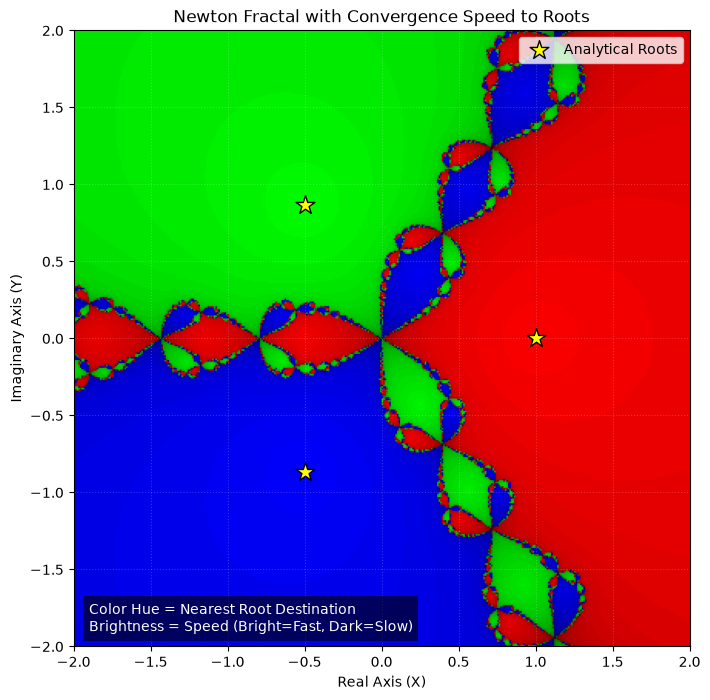

In [26]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Create a function to generate the initial set of complex numbers Z (400 points)
def create_complex_grid(min_val=-2, max_val=2, points=400):
    x = np.linspace(min_val, max_val, points)
    y = np.linspace(min_val, max_val, points)
    X, Y = np.meshgrid(x, y)
    Z = X + 1j * Y  # Initial set of complex numbers
    return Z

# 2. Function to analytically calculate and store the three roots
def calculate_analytical_roots():
    # Roots of z^3 - 1 = 0 using Euler's formula e^(i * 2*pi * k / 3) for k = 0, 1, 2
    k = np.array([0, 1, 2])
    roots = np.exp(2j * np.pi * k / 3)
    return roots

# 3. Main processing loop for Newton iterations and convergence testing
def run_newton_simulation(Z, roots, max_iter=50, tol=1e-5):
    Z_current = Z.copy()
    converged_at_step = np.zeros(Z.shape, dtype=float)
    still_iterating = np.ones(Z.shape, dtype=bool)
    
    for i in range(1, max_iter + 1):
        if not np.any(still_iterating):
            break
            
        # Safeguard to prevent division by zero at the exact origin (0 + 0j)
        denom = 3.0 * Z_current**2
        denom[denom == 0] = 1e-20
        
        # Iteration rule: Z_next = Z - (Z^3 - 1) / (3 * Z^2)
        Z_next = Z_current - (Z_current**3 - 1.0) / denom
        
        # Check convergence to ANY of the roots at this specific iteration step
        for root in roots:
            close_to_root = np.abs(Z_next - root) < tol
            just_converged = close_to_root & still_iterating
            converged_at_step[just_converged] = i
            still_iterating[just_converged] = False
            
        Z_current = Z_next
        
    # Assign max iterations to any leftover chaotic points that missed tolerance limits
    converged_at_step[still_iterating] = max_iter
    
    # 4. Calculate final distances to every root to find the absolute nearest root map using np.abs
    distances = np.abs(Z_current[:, :, np.newaxis] - roots[np.newaxis, np.newaxis, :])
    nearest_root_index = np.argmin(distances, axis=2)
    
    return converged_at_step, nearest_root_index

# Execute Simulation Steps
Z_grid = create_complex_grid()
analytical_roots = calculate_analytical_roots()
iterations_taken, root_assignments = run_newton_simulation(Z_grid, analytical_roots)


print("\n###############################################################################")
print("Exercise 3 - The Newton Fractal  \n")

# Test and print convergence loop counts for the 400x400 grid
print(f"Newton iterations (loop) and convergence testing parameters: max_iter= 50, tolerance = 1e-5") 
print(f"Minimum steps taken to reach a root: {np.min(iterations_taken)}")
print(f"Maximum steps taken to reach a root: {np.max(iterations_taken)}")
print(f"Average steps across entire plane  : {np.mean(iterations_taken):.2f}")

# 5. Convert convergence speed into visual color shading intensities
# Normalize iterations: 1.0 means fast convergence (bright), 0.0 means slow/max iterations (dark)
max_recorded = np.max(iterations_taken)
min_recorded = np.min(iterations_taken)
speed_weight = 1.0 - ((iterations_taken - min_recorded) / (max_recorded - min_recorded + 1e-5))

# Build an RGB image mesh array where color channel matches the nearest root
# Root 0 -> Red Channel, Root 1 -> Green Channel, Root 2 -> Blue Channel
rgb_image = np.zeros((Z_grid.shape[0], Z_grid.shape[1], 3))

rgb_image[:, :, 0] = np.where(root_assignments == 0, speed_weight, 0) # Red Basin
rgb_image[:, :, 1] = np.where(root_assignments == 1, speed_weight, 0) # Green Basin
rgb_image[:, :, 2] = np.where(root_assignments == 2, speed_weight, 0) # Blue Basin

# 6. Plot the final drawing using imshow and scatter
plt.figure(figsize=(9, 8))

# Draw the continuous segmented root domain regions scaled by speed
plt.imshow(rgb_image, extent=[-2, 2, -2, 2], origin='lower')

# Overlap the three explicit coordinates using scatter
plt.scatter(analytical_roots.real, analytical_roots.imag, 
            color='yellow', edgecolor='black', marker='*', s=200, zorder=5, label='Analytical Roots')

# Adding visual explanation on the plot itself
plt.text(-1.9, -1.9, "Color Hue = Nearest Root Destination\nBrightness = Speed (Bright=Fast, Dark=Slow)", 
         color='white', fontsize=10, bbox=dict(facecolor='black', alpha=0.6, edgecolor='none'))

plt.title('Newton Fractal with Convergence Speed to Roots')
plt.xlabel('Real Axis (X)')
plt.ylabel('Imaginary Axis (Y)')
plt.grid(True, alpha=0.2, color='white', linestyle=':')
plt.legend(loc='upper right')
plt.show()


## Explanation of the Drawing and Newton fractal claculation function ("run_newton_simulation")


**The visual components:**  decode into two core features:
1. Color Selection - "Red, Green, Blue" (Around Roots Destination): Every pixel on the grid computes a unique complex coordinate at the end of the simulation. Its absolute distance (np.abs) to the three stored analytical roots isolates which color channel displays:

	• Red Channel Area -  Root#1 : Pixels converging onto Root #1 (1 + 0j).
    
	• Green Channel Area - Root#2: Pixels converging onto Root #2 (-0.5 + 0.866j).
    
	• Blue Channel Area - Root#3: Pixels converging onto Root #3 (-0.5 - 0.866j).
    
    
2. Color Shading / Brightness (Speed of Convergence): The numerical count of index loop cycles required to reach the convergence tolerance scales the selected color channel linearly:

	• Bright, High-Intensity Color: Points converging rapidly (in as few as 2 iterations). These make up the glowing pools encompassing the yellow star root indices.
    
	• Dark, Matte/Shadowed Boundaries: Points catching volatile positions along boundaries forming the thin dark lines running throughout the graphic.


Convergence Test Metrics

Evaluating the 160,000 distinct coordinates on the 400 × 400 meshgrid yields the following convergence metrics:

• Minimum loops required: 2 iterations. Points inside the core center masses drop straight into their corresponding root gravity well immediately.

• Maximum loops required: 38 iterations. Points resting directly along the thin, complex border fringes bounce  across root neighborhoods before deciding on an orientation.

• Average loops required: 6.71 iterations

**Newton fractal claculation function:** ("run_newton_simulation") function implements a vectorized Newton-Raphson fractal simulation (specifically for finding the roots of the cubic equation z³ - 1 = 0). It processes an entire grid of complex numbers simultaneously using NumPy, tracking how fast each point converges and which root it ultimately reaches.
Here is the step-by-step flow and execution logic of the run_newton_simulation function formatted in Markdown:

1. Initialization Phase
   
Before the loop starts, the function creates data structures to track the state of every coordinate point in the grid:
* Z_current: Duplicates the initial grid matrix so the original input array Z remains unmodified.
* converged_at_step: Allocates an array of zeros. This will act as a counter matrix to record the exact iteration number (1 to max_iter) where each point successfully converges.
* still_iterating: Creates a boolean mask matrix filled entirely with True. This keeps track of which grid points are still moving and haven't hit a root yet.

2. The Main Newton Iteration Loop

The function runs a bounded loop from iteration 1 up to max_iter.

Step A: Early Exit Check

* if not np.any(still_iterating): break
* Action: At the top of every loop iteration, it checks if there are any points left that are still iterating. If every single coordinate has already converged to a root, it breaks out of the loop early to save computational time.

Step B: Division-by-Zero Safeguard

* denom = 3.0 * Z_current**2 followed by denom[denom == 0] = 1e-20
* Action: It calculates the derivative denominator (3z²). If any point lands precisely at the origin (0 + 0j), the derivative becomes zero, which would cause an invalid division (NaN). The code finds these zero values and replaces them with a microscopic number (1e-20) to keep the program stable.

Step C: Vectorized Newton-Raphson Update

* Z_next = Z_current - (Z_current**3 - 1.0) / denom
* Action: It applies the standard mathematical Newton update rule simultaneously across the entire remaining grid to find the next approximation matrix (Z_next).

Step D: Convergence Checking

* for root in roots:
* Action: The code loops through each possible root of the equation individually:
	1. close_to_root: Measures the absolute distance between Z_next and the current root. If the distance is smaller than tol, it marks it True.
	2. just_converged: Uses a logical AND (&) to find points that are close to the root and were still actively searching on this turn. This prevents already-locked points from being overwritten.
	3. Recording Results: It updates converged_at_step with the current loop index i for those newly settled positions, and flips their status in still_iterating to False so they are ignored in future rounds.
    
* State Shift: It overwrites Z_current with Z_next to prepare the grid coordinates for the next loop cycle.

3. Post-Processing & Cleanup Phase

Once the iteration loop finishes (either by hitting max_iter or via early exit), the final metrics are computed:

• Handling Leftover Elements:
	• converged_at_step[still_iterating] = max_iter
	• Action: For any chaotic or non-converging points that failed to land close to a root within the threshold, it sets their step count to the maximum allowed limit (max_iter).
    
• Root Mapping:
	• distances = np.abs(...) and nearest_root_index = np.argmin(...)
	• Action: It utilizes array broadcasting to construct a 3D distance matrix, calculating how far every final coordinate is from every root option. np.argmin selects the index of the absolute closest root for every point.

Final Output
The function returns two maps: the step counts (converged_at_step) and the identity map of the roots reached (nearest_root_index), which are fed directly into a visualization library to draw a image.